# Preparar datos auditables para una política de frontera

**Pregunta:** ¿Cómo permiten las particiones congeladas y la normalización solo de entrenamiento reproducir un experimento sintético sin exponer casos reservados?

**Nivel:** 2 : Método en práctica.

## Objetivos

Al terminar podrás seguir un grafo generado desde su semilla y familia hasta un registro de partición congelado; distinguirás por qué separar semillas, familias y casos del producto responde a riesgos de fuga distintos; ajustarás estadísticas nombradas usando solo registros de entrenamiento; y reproducirás el resumen que vincula esas estadísticas con sus filas de origen. También cuantificarás cómo cambian la familia y el tamaño la población de atributos. El ejercicio usa los contratos de datos de la canalización del repositorio sobre un subconjunto pequeño y acotado para ejecutarlo rápidamente. Enseña preparación de datos, no entrenamiento ni calidad del modelo. Un resumen correcto demuestra reproducibilidad byte a byte para las entradas declaradas; no demuestra que los grafos sintéticos representen una mina operativa.

## Preparación

Ejecuta desde la raíz del repositorio con el entorno fijado para notebooks. El generador de origen, el constructor de particiones, el validador y el normalizador se importan desde la canalización de datos; las celdas no copian sus algoritmos. El registro de particiones comprometido es la autoridad del experimento candidato, mientras se usa aquí un prefijo compacto de las filas de entrenamiento para mantener la lección práctica. Las filas de validación y prueba se inspeccionan solo como metadatos. Nunca se entregan al ajuste. Las dos versiones indicadas corresponden al entorno de notebooks. Ejecuta el notebook completo en un kernel nuevo para regenerar conteos y figuras desde los archivos congelados.

```bash
python -m pip install numpy==2.5.1 matplotlib==3.11.2
```

### Versiones de paquetes

La siguiente celda informa las versiones instaladas antes de procesar datos.

### Informa las versiones exactas del entorno antes de procesar datos.

In [1]:
# Informa las versiones exactas del entorno antes de procesar datos.
# Report exact runtime pins before processing data.
import importlib.metadata
print({name: importlib.metadata.version(name) for name in ('numpy', 'matplotlib')})

{'numpy': '2.5.1', 'matplotlib': '3.11.2'}


### Importa las API comprometidas del motor; esta lección no copia sus algoritmos.

In [2]:
# Importa las API comprometidas del motor; esta lección no copia sus algoritmos.
from pathlib import Path
import json, sys
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path.cwd().parents[2]
sys.path.insert(0, str(ROOT / 'data-pipeline'))
from pipeline.model.frontier_data import FEATURE_NAMES, GENERATOR_VERSION, generate_graph
from pipeline.model.frontier_features import fit_training_normalizer, normalizer_contract, feature_contract_sha256
from pipeline.model.frontier_policy import validate_split_manifest
from pipeline.model.frontier_splits import build_split_manifest, manifest_sha256

## Datos

Cada fila del generador declara exactamente cuatro campos: una semilla entera, una familia de grafos, un número de nodos y una versión del generador. La semilla determina el flujo pseudoaleatorio; la familia determina el patrón de precedencia; y el tamaño determina el número de nodos de decisión. El grafo aporta siete atributos nombrados junto con vectores de recursos y aristas de precedencia. El generador es determinista con la misma semilla, familia, tamaño, períodos y versión de implementación. Estos registros son casos sintéticos para desarrollar métodos. No son planes mineros, instancias MineLib, datos de clientes ni evidencia de desempeño operativo. Los identificadores de casos de referencia del producto se mantienen aparte en el registro congelado y se excluyen de cada partición de ajuste y selección del modelo.

La política separa deliberadamente la familia de grafos entre entrenamiento, validación y prueba. Así, la evaluación posterior mide transferencia entre estructuras y no solo memorización de semillas aleatorias cercanas. Rangos de semillas distintos evitan reutilizar exactamente el flujo aleatorio, mientras que asignar familias distintas da una separación estructural más fuerte. El conjunto de casos del producto queda sellado como evaluación solamente; no debe influir en el ajuste del normalizador, las decisiones de entrenamiento ni la selección basada en validación. Lee el manifiesto antes de cambiarlo: modificar una familia, semilla, regla de tamaño, versión del generador o lista de casos cambia la pregunta científica y debe crear un recibo con nueva versión.

### Valida la partición congelada e inspecciona los campos versionados del recibo de publicación.

In [3]:
# Valida la partición congelada e inspecciona los campos versionados del recibo de publicación.
index = json.loads((ROOT / 'data/derived/manifests/index.json').read_text(encoding='utf-8'))
manifest = build_split_manifest([row['case_id'] for row in index['cases']])
partition_counts = validate_split_manifest(manifest)
manifest_digest = manifest_sha256(manifest)
print({'generator': GENERATOR_VERSION, 'counts': partition_counts, 'manifest_sha256': manifest_digest})
receipt_schema = json.loads((ROOT / 'docs/contracts/schemas/frontier-release.schema.json').read_text(encoding='utf-8'))
case_schema = receipt_schema['$defs']['case']
print({'receipt_fields': receipt_schema['required'],
       'case_fields': case_schema['required'],
       'case_statuses': case_schema['properties']['status']['enum']})

{'generator': 'frontier-graphs/1.0.0', 'counts': {'train': 1000, 'validation': 200, 'test': 500, 'product_cases': 13}, 'manifest_sha256': '18860c8a361576ba924ec95fd5dfe9d58c8a37a3466a1c17bb9765ddfc81350c'}
{'receipt_fields': ['schema', 'created_at_utc', 'product_version', 'engine_version', 'source_commit', 'training_source_commit', 'checkpoint_sha256', 'checkpoint_members_sha256', 'feature_contract_sha256', 'split_sha256', 'case_index_sha256', 'baseline', 'cases', 'summary', 'redistribution'], 'case_fields': ['case_id', 'product_version', 'engine_version', 'source_commit', 'checkpoint_sha256', 'feature_contract_sha256', 'status', 'failure_reason'], 'case_statuses': ['complete', 'partial', 'failed', 'unavailable']}


## Método

Primero carga el índice de casos comprometido y reconstruye el manifiesto aprobado mediante la API del motor. El validador comprueba que las listas estén bien formadas y sean disjuntas. Luego toma solo una muestra pequeña de entrenamiento e inspecciona los grafos generados. La API del normalizador consume los registros, regenera sus matrices de atributos y ajusta medias y escalas usando únicamente esos valores de entrenamiento.

Para el atributo j, el valor estandarizado almacenado es zᵢⱼ = (xᵢⱼ − μⱼ) / σⱼ. La media y la escala se calculan sobre los nodos de las filas de entrenamiento. La implementación trata explícitamente los atributos constantes. El resumen de datos de entrenamiento procesa cada semilla y los bytes exactos de atributos float32 little-endian contiguos, en orden de filas. Un segundo resumen de JSON canónico vincula ese resumen con el contrato nombrado del normalizador. Así se hacen visibles cambios en el orden, las semillas, los valores generados, los nombres de atributos o las estadísticas. Es un recibo de integridad, no una afirmación criptográfica sobre la validez científica del generador.

La API rechaza un conjunto vacío, semillas duplicadas, un esquema de fila distinto, etiquetas de partición que no sean entrenamiento y nombres de atributos que introduzcan identificadores o resultados. El manifiesto congelado contiene las particiones completas de 1.000/200/500 filas; el ajuste completo pertenece al proceso de entrenamiento separado. Para limitar el tiempo, esta lección ajusta solo 24 filas de entrenamiento. Sus estadísticas pequeñas sirven para comprender la canalización y nunca deben reemplazar al normalizador completo ni presentarse como evidencia de un modelo entrenado.

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

$$h = \mathrm{SHA256}(\mathrm{canonicalJSON}(\mathrm{normalizer}, h_{train}))$$

### Genera una muestra pequeña de entrenamiento y deja intactas las filas reservadas.

In [4]:
# Genera una muestra pequeña de entrenamiento y deja intactas las filas reservadas.
sample_rows = manifest['train'][:24]
sample_graphs = [
    generate_graph(row['seed'], row['family'], row['size'])
    for row in sample_rows
]
family_sizes = {
    family: [graph.size for graph in sample_graphs if graph.family == family]
    for family in sorted({graph.family for graph in sample_graphs})
}
print({
    name: (len(values), min(values), max(values))
    for name, values in family_sizes.items()
})

{'benched': (24, 32, 125)}


### Grafica los tamaños de los grafos de entrenamiento por estructura declarada.

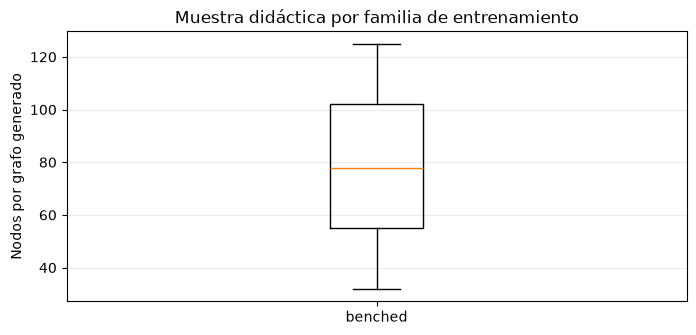

In [5]:
# Grafica los tamaños de los grafos de entrenamiento por estructura declarada.
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([values for values in family_sizes.values()], tick_labels=list(family_sizes))
ax.set_ylabel('Nodos por grafo generado')
ax.set_title('Muestra didáctica por familia de entrenamiento')
ax.grid(axis='y', alpha=.25)
plt.show()

### Lectura de tamaños por familia

El gráfico muestra el rango de tamaños de nodo generado por la muestra pequeña y fija de semillas, agrupada por familia. Los rangos distintos reflejan la regla de muestreo, no el resultado de una política aprendida. Las etiquetas familiares codifican estructuras de precedencia distintas; por eso la evaluación posterior entre ellas prueba transferencia estructural y no solo variación aleatoria. El subconjunto es ilustrativo: describe el protocolo con los conteos del manifiesto, no con esta figura.

### Ajusta el normalizador nombrado y vincula sus estadísticas con los bytes de origen.

In [6]:
# Ajusta el normalizador nombrado y vincula sus estadísticas con los bytes de origen.
normalizer, training_data_digest = fit_training_normalizer(sample_rows)
normalizer_data = normalizer_contract(normalizer)
feature_digest = feature_contract_sha256(normalizer, training_data_digest)
receipt = {'rows_used': len(sample_rows), 'node_rows': normalizer.train_rows}
receipt['training_data_sha256'] = training_data_digest
receipt['feature_contract_sha256'] = feature_digest
print(receipt)
print(normalizer_data)

{'rows_used': 24, 'node_rows': 1881, 'training_data_sha256': '83c5c5bc44c0fdfe3b9b3d07813ddaf7bf943bba6c30d4278cfc938742500e2a', 'feature_contract_sha256': '6ad77afc247156bacc4b89c82662486c37a9ebbb0b6149cdc1a32702affec70e'}
{'schema_version': '1.0.0', 'feature_names': ['value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count'], 'mean': [-0.10564063837144712, 0.4525289130592714, 0.49760765550239233, 0.44143848606830405, 0.48086124925157736, 0.7820308346624136, 0.7820308346624136], 'scale': [0.3316759874458885, 0.17511919303690698, 0.4999942766550476, 0.22411597415101406, 0.31014900211886054, 0.33779521100541904, 0.3478747217256935], 'train_rows': 1881, 'sha256': 'bc6c67759358103c231d54b388961020b7012e5998668304e6925fbd30838eaa'}


### Aplica las estadísticas de entrenamiento y comprueba que los valores sean finitos.

In [7]:
# Aplica las estadísticas de entrenamiento y comprueba que los valores sean finitos.
raw = np.concatenate([graph.node_features for graph in sample_graphs], axis=0)
scaled = (raw - np.asarray(normalizer.mean)) / np.asarray(normalizer.scale)
print('orden de atributos:', list(FEATURE_NAMES))
print('dimensiones originales:', raw.shape, 'escalados finitos:', bool(np.isfinite(scaled).all()))

orden de atributos: ['value_norm', 'tonnage_norm', 'plant_use_fraction', 'grade_norm', 'depth_fraction', 'predecessor_count', 'successor_count']
dimensiones originales: (1881, 7) escalados finitos: True


### Compara valores originales y estandarizados sin afirmar alineación de distribuciones.

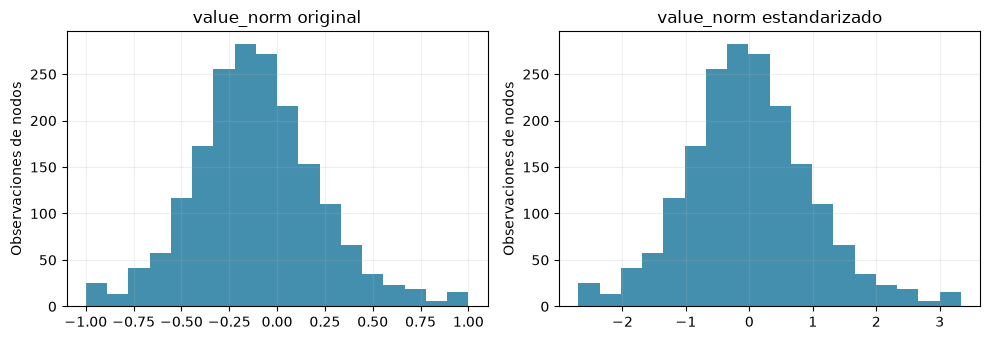

In [8]:
# Compara valores originales y estandarizados sin afirmar alineación de distribuciones.
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
series = ((raw[:, 0], 'value_norm original'), (scaled[:, 0], 'value_norm estandarizado'))
for axis, (values, title) in zip(axes, series):
    axis.hist(values, bins=18, color='#247ba0', alpha=.85)
    axis.set_title(title)
    axis.set_ylabel('Observaciones de nodos')
    axis.grid(alpha=.2)
plt.tight_layout()
plt.show()

### Lectura de escalas de atributos

Cada panel muestra el mismo atributo en escalas original y estandarizada para entrenamiento. El centrado y escalado se ajustan solo con el pequeño subconjunto de entrenamiento; el eje vertical representa observaciones de nodos, no minas independientes. La forma sigue siendo informativa después de escalar, por lo que la normalización no debe describirse como alineación de distribuciones. Las familias reservadas pueden seguir siendo muy distintas.

### Vistas comparativas

Tres vistas responden preguntas de datos distintas. La primera compara los tamaños de nodo por familia en una muestra sintética fija y muestra por qué la familia tiene significado estructural. La segunda compara distribuciones de atributos originales y estandarizados para el subconjunto de la lección; centrar y escalar puede facilitar el trabajo de un optimizador, pero no elimina el cambio de distribución. La tercera varía el tamaño del grafo manteniendo fija la familia y la semilla, para hacer visibles los efectos asociados al tamaño.

La muestra medida no incluye etiquetas de resultado ni es un benchmark. Una figura aparentemente equilibrada no demuestra que el generador completo lo esté. La estandarización tampoco vuelve intercambiables las observaciones de validación y prueba con las de entrenamiento. Sus familias son deliberadamente distintas, por lo que una caída posterior puede reflejar dificultad de transferencia estructural. Corresponde informar e inspeccionar los modos de falla, no reajustar usando datos reservados.

### Varía el tamaño con familia y semilla constantes.

In [9]:
# Varía el tamaño con familia y semilla constantes.
size_rows = [
    generate_graph(seed, 'branching', size)
    for size in (32, 96, 256)
    for seed in (71, 72, 73)
]
size_summary = [
    (graph.size, float(graph.node_features[:, 4].mean()),
     float(graph.node_features[:, 5].mean()))
    for graph in size_rows
]
print('tamaño, profundidad media, precedencia media:', size_summary[:3])

tamaño, profundidad media, precedencia media: [(32, 0.643750011920929, 0.515625), (32, 0.643750011920929, 0.515625), (32, 0.643750011920929, 0.5)]


### Visualiza la respuesta del atributo de profundidad ante el tamaño.

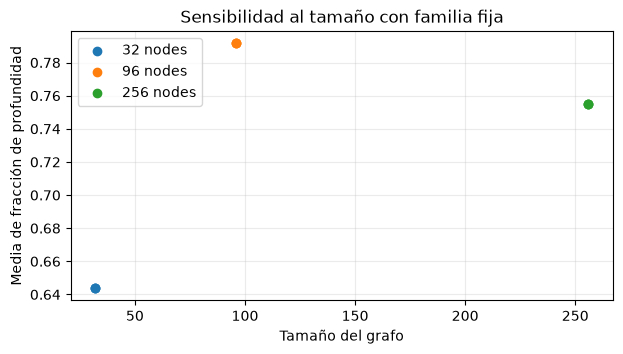

In [10]:
# Visualiza la respuesta del atributo de profundidad ante el tamaño.
fig, ax = plt.subplots(figsize=(7, 3.5))
for size in (32, 96, 256):
    rows = [row for row in size_summary if row[0] == size]
    ax.scatter([size] * len(rows), [row[1] for row in rows], label=f'{size} nodes')
ax.set_xlabel('Tamaño del grafo')
ax.set_ylabel('Media de fracción de profundidad')
ax.set_title('Sensibilidad al tamaño con familia fija')
ax.grid(alpha=.25)
ax.legend()
plt.show()

### Lectura de sensibilidad al tamaño

La familia y la semilla permanecen fijas mientras cambia el tamaño. Las curvas muestran comportamientos asociados al tamaño, como profundidad y grado, mientras atributos acotados de valor y tonelaje pueden conservar escalas similares. Es una vista de sensibilidad del generador, no una prueba de calidad del modelo. Un depósito real puede tener estructuras ajenas a estos patrones; el tamaño por sí solo no demuestra representatividad.

### Repite el ajuste con menos filas y conserva el resumen del manifiesto.

In [11]:
# Repite el ajuste con menos filas y conserva el resumen del manifiesto.
for count in (8, 24):
    fitted, digest = fit_training_normalizer(manifest['train'][:count])
    report = {'training_graphs': count, 'node_rows': fitted.train_rows}
    report['mean_value_norm'] = round(float(fitted.mean[0]), 5)
    report['data_sha256_prefix'] = digest[:12]
    print(report)
print('El manifiesto congelado se mantiene:', manifest_digest)

{'training_graphs': 8, 'node_rows': 368, 'mean_value_norm': -0.04913, 'data_sha256_prefix': '4dd2bab9cce9'}
{'training_graphs': 24, 'node_rows': 1881, 'mean_value_norm': -0.10564, 'data_sha256_prefix': '83c5c5bc44c0'}
El manifiesto congelado se mantiene: 18860c8a361576ba924ec95fd5dfe9d58c8a37a3466a1c17bb9765ddfc81350c


## Resultados

**Respuesta:** El registro congelado contiene 1.000 filas de entrenamiento, 200 de validación y 500 de prueba. La tabla impresa informa los conteos congelados, semillas únicas, pertenencia familiar, tamaño de la muestra didáctica, número de nodos usados al ajustar el normalizador y los dos resúmenes de reproducibilidad. Responde la pregunta: la preparación es auditable porque el esquema de filas, la política de partición, el límite de ajuste solo con entrenamiento y los hashes de contenido están explícitos y se verifican por separado. No indica que la política haya aprendido una regla útil de planificación.

El resumen de atributos muestra la media y escala ajustadas por nombre declarado. Estos valores describen solo las 24 filas de la lección. Si aumentas el tamaño del subconjunto, deberían cambiar las estadísticas y el resumen de datos, mientras el resumen del manifiesto congelado permanece fijo. Al regenerar con los mismos archivos, orden y subconjunto, los resultados deben coincidir. Esta diferencia ayuda a diagnosticar si un cambio proviene del protocolo o simplemente de la muestra pequeña elegida para el tutorial.

### Contrato de evidencia de publicación

El recibo de publicación cierra la cadena de procedencia solo después de evaluar la política congelada en cada caso declarado del producto. Sus campos principales vinculan las versiones del producto y del motor, los commits de entrenamiento y evaluación, los cinco hashes de checkpoints, el contrato de atributos, la partición, el índice de casos, la identidad de la línea base, los trece resultados retenidos y los límites de redistribución. Un caso con planificación requiere el hash de su traza. Un caso fallido o no disponible requiere una razón; no puede desaparecer del conteo. El resumen del conjunto de checkpoints se calcula sobre los hashes ordenados, por lo que cambiar el orden de los miembros también cambia su identidad.

Este contrato difiere del resumen de datos de entrenamiento anterior: uno vincula los datos ajustados y el otro vincula un candidato de publicación con el modelo y los archivos de reproducción exactos. El esquema verifica la forma y los requisitos condicionales. El validador Python además comprueba la identidad y orden de los casos, las versiones y commits compartidos, y los totales por estado. Se necesitan ambos controles porque un JSON válido no demuestra que el experimento sea coherente. Si falta el recibo, no existe evidencia completa de publicación por caso. En este checkout se perdió la salida de la evaluación sintética reservada durante la serialización final y quedó registrada como consumida; por eso el recibo debe permanecer ausente. Esta lección inspecciona la definición del contrato y no afirma rendimiento.

$$h_{members}=\mathrm{SHA256}(h_1\Vert h_2\Vert h_3\Vert h_4\Vert h_5)$$

Un caso planificado lleva el resumen de su traza; un caso fallido conserva una razón explícita.

### Sensibilidad y límites

Cambia la familia y el tamaño en la celda de comparación final e inspecciona si se mueven las distribuciones. Repite el ajuste con 8, 24 y 48 filas de entrenamiento y compara medias de atributos y el resumen de datos. Son análisis de sensibilidad de la población de preprocesamiento, no selección de hiperparámetros: no elijas el subconjunto porque produzca resultados posteriores atractivos. El experimento aprobado usa la lista completa de entrenamiento congelada.

Las familias generadas codifican pocos patrones sintéticos de precedencia y relaciones económicas y de recursos sencillas. No modelan incertidumbre geotécnica, interacción de flota, modelos detallados de bloques, precios cambiantes ni restricciones operativas humanas. El normalizador solo reescala atributos; no corrige un generador débil ni fugas en una variable objetivo. Separar semillas no basta si los casos comparten estructura; por ello el protocolo también particiona familias. La separación familiar es una prueba deliberada de estrés, no una afirmación de que las familias cubran depósitos reales. Una conclusión robusta requiere los experimentos reservados posteriores, intervalos de incertidumbre, el registro de fallas y casos auténticos del producto bajo el diseño de evaluación aprobado.

Estas particiones responden preguntas distintas. Reservar semillas prueba la dependencia de un flujo pseudoaleatorio; reservar familias prueba la transferencia a estructuras de precedencia distintas; un estudio con datos reales también debe reservar depósitos completos cuando las observaciones comparten una mina. Este protocolo sintético solo aborda las dos primeras preguntas y no demuestra transferencia a minas operativas. El normalizador se ajusta con filas de entrenamiento y después se aplica sin cambios. La optimización PPO y la selección del checkpoint usan entrenamiento y validación; la partición de prueba permanece sellada hasta congelar el ensamble.

### Usa tus propios datos

Usa esta lección para comprender la interfaz, no para pegar datos operacionales en el generador sintético. El esquema actual requiere semilla, familia, tamaño y versión; los modelos reales de bloques no se convierten en observaciones válidas asignándoles esos campos. Un flujo con datos reales requiere documentar su origen, derechos y consentimiento, mapeo de esquema, reglas de valores faltantes, unidades, unidad de partición y validación independiente. Separa por mina o depósito cuando observaciones de un mismo origen puedan aparecer a ambos lados. Mantén identificadores y resultados fuera del ajuste de atributos. Ajusta cada transformación con los casos de entrenamiento, congélala y aplícala sin cambios a validación y prueba.

Para un experimento local con el mismo contrato sintético, cambia la cantidad de filas de entrenamiento seleccionadas o inspecciona otra familia declarada y vuelve a ejecutar todas las comprobaciones. No edites el registro comprometido para adaptar datos personalizados. Un nuevo generador o conjunto de datos necesita un contrato y recibo versionados para distinguirlo del experimento que enseña esta lección.

Al desarrollar una nueva familia sintética, primero versiona su generador y declara los campos disponibles antes de programar. Define los grupos de entrenamiento, validación y prueba antes de generar resultados; mantén separada la lista de casos del producto. Llama a `fit_training_normalizer` solo con filas de entrenamiento y guarda juntos `normalizer_contract`, `training_data_sha256` y `feature_contract_sha256`. La partición de validación puede seleccionar checkpoints según la regla predeclarada. Abre la prueba una sola vez, después de congelar el ensamble; no la uses para elegir atributos, ajustar escalas ni cambiar el generador. Si cambia el esquema, la familia o la regla de partición, crea un manifiesto y recibo nuevos en lugar de comparar los resultados como si fueran el mismo experimento.

Trata el resumen de datos como un límite de reproducibilidad, no solo como un checksum. Si cambia, compara la versión del generador, el orden de filas, los conteos de semillas y familias, y el orden de atributos antes de mirar puntuaciones. Una escala casi nula puede indicar un atributo constante; la protección explícita evita dividir por cero, pero no vuelve informativo ese atributo. Guarda el contrato completo del normalizador con cada checkpoint. Reutilizar pesos con otro orden de atributos o estadísticas ajustadas cambia el significado de las entradas aunque las dimensiones del tensor sigan coincidiendo.

## Resumen

Seguiste el recorrido desde una especificación versionada de grafos sintéticos hasta particiones disjuntas del manifiesto, atributos de nodo nombrados, un normalizador ajustado solo con entrenamiento y hashes reproducibles. El subconjunto de la lección es demasiado pequeño para afirmar algo sobre la política. La canalización completa usa todas las filas congeladas de entrenamiento y escribe el recibo y los artefactos del modelo fuera del repositorio de fuentes. Las filas reservadas permanecen invisibles durante el ajuste y la selección.

La regla práctica es tratar el preprocesamiento como parte del modelo: el orden de atributos, los valores ajustados, las filas de origen y el resumen viajan juntos. Si uno cambia, reconstruye y documenta el artefacto de entrenamiento. Cuando terminen el entrenamiento y la evaluación aprobados por separado, una lección empírica posterior podrá usar esos recibos e informar resultados. Hasta entonces, este notebook solo enseña contratos de datos y preprocesamiento.

## Referencias

Las actas de planificación aportan contexto sobre decisiones con restricciones de precedencia. Roberts y colegas estudian validación cuando las observaciones tienen estructura espacial o jerárquica; Schulman y colegas presentan la optimización proximal de políticas; y la guía de scikit-learn explica por qué el preprocesamiento aprendido debe ajustarse solo con entrenamiento. Estas fuentes respaldan decisiones generales del protocolo, no resultados empíricos de PhaseFlow. La implementación demostrada aquí la definen la canalización versionada y el manifiesto congelado del producto.

- [Actas ICAPS, volumen 33, número 1](https://doi.org/10.1609/icaps.v33i1.27244)
- [Actas FLAIRS, volumen 35](https://doi.org/10.32473/flairs.v35i.130584)
- [Roberts et al., validación cruzada para datos estructurados](https://doi.org/10.1111/ecog.02881)
- [Schulman et al., Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347)
- [scikit-learn, errores comunes y prácticas recomendadas](https://scikit-learn.org/stable/common_pitfalls.html)